# Smarter Dispatch at the Noon Rush
### INFORMS TSL Data-Driven Research Challenge · Meituan on-demand food delivery

**BMN 616 · Advanced Optimization Techniques for Managers · Project (Option C: real competition data) · Team of 3**

At every dispatch moment Meituan must decide which courier takes which waiting order. The challenge's first sample question asks for assignment methods that cut the courier's **detour** (extra distance) and the **delays** beyond the promised delivery time, fast enough to run every 30 to 60 seconds.

This notebook:

1. checks our data pipeline against the published data paper (Wang et al. 2025);
2. builds a **digital twin** of courier routes, calibrated on 77,000 direct trips and validated on held-out days;
3. formulates dispatch as a **set-partitioning model in Pyomo**: couriers "bid" on single orders and 2–3 order bundles, like the Mars combinatorial auction from class;
4. re-solves Meituan's **24 real noon-peak dispatch moments** (12,994 orders) and compares with what Meituan actually did.

**Run it.** In Google Colab: upload the challenge repository zip (or clone it), then *Runtime → Run all*. Pyomo and the free HiGHS solver install in the first cell. A full run takes about 10 minutes; set `QUICK = True` for a quicker run on 6 of the 24 dispatch moments.

*This research was supported by data provided by Meituan.* The data is licensed CC BY-NC 4.0 for non-commercial academic use and may not be redistributed.

In [1]:
%pip install -q pyomo highspy

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, glob, zipfile, json, time, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

QUICK = False          # True: 6 of the 24 dispatch moments, for a fast first run

def find_data_dir():
    # 1) an explicit path, 2) an unzipped repo nearby, 3) a repo zip uploaded to Colab
    cands = [os.environ.get("MEITUAN_DATA", ""), ".", "Meituan-INFORMS-TSL-Research-Challenge-main",
             "meituan_informs_data", "/content/Meituan-INFORMS-TSL-Research-Challenge-main", "/content/meituan_informs_data"]
    for c in cands:
        if c and os.path.exists(os.path.join(c, "dispatch_waybill_meituan.csv")):
            return c
    for z in glob.glob("*.zip") + glob.glob("/content/*.zip"):
        with zipfile.ZipFile(z) as f:
            f.extractall(".")
        hit = glob.glob("**/dispatch_waybill_meituan.csv", recursive=True)
        if hit:
            return os.path.dirname(hit[0])
    raise FileNotFoundError("Upload the challenge repo zip, or set MEITUAN_DATA to the folder with the CSV files.")

DATA_DIR = find_data_dir()
print("data folder:", DATA_DIR)

C_MT, C_OPT, C_ACC, C_ONE, C_INK, C_MUTE = "#9AA3AF", "#FF6B35", "#2EC4B6", "#5B5F97", "#1F2430", "#6B7280"
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlelocation": "left"})
os.makedirs("figures", exist_ok=True)

data folder: /home/claude/meituan_data


## 1 · The model code

Two small modules, written to disk so the notebook stays readable:

* `dispatch_core.py`: data loading, geometry, the travel-time calibration, and the **route simulator**. A courier's remaining stops are rebuilt from their on-hand orders. A new order is inserted at its cheapest position (pickup before drop). The simulator reports added km, added late minutes and new late deliveries.
* `dispatch_models.py`: **column generation** (courier bids on order bundles), the courier **acceptance model**, and the **Pyomo set-partitioning model**.

In [3]:
%%writefile dispatch_core.py
"""Core data pipeline and route-insertion costs for the Meituan dispatch project.

Everything here is plain Python + numpy + pandas so it runs in Colab. The Pyomo models live in dispatch_models.py.
"""
import ast
import itertools
import numpy as np
import pandas as pd

# ----------------------------------------------------------------------------- loading


def load_tables(data_dir):
    """Read the four challenge tables from data_dir (the folder that holds the CSV files)."""
    import os, zipfile
    wb_csv = os.path.join(data_dir, "all_waybill_info_meituan_0322.csv")
    if not os.path.exists(wb_csv):
        with zipfile.ZipFile(wb_csv + ".zip") as z:
            z.extract("all_waybill_info_meituan_0322.csv", data_dir)
    wb = pd.read_csv(wb_csv, index_col=0)
    dw = pd.read_csv(os.path.join(data_dir, "dispatch_waybill_meituan.csv"), index_col=0)
    dr = pd.read_csv(os.path.join(data_dir, "dispatch_rider_meituan.csv"), index_col=0)
    cw = pd.read_csv(os.path.join(data_dir, "courier_wave_info_meituan.csv"))
    dr["onhand"] = dr["courier_waybills"].apply(ast.literal_eval)   # these are ORDER ids (checked: 99.4% match)
    return wb, dw, dr, cw


# ----------------------------------------------------------------------------- geometry

LAT0, LNG0 = 45.88, 174.55          # rough centre of the (shifted) city, degrees


def to_xy(lat_e6, lng_e6):
    """Shifted lat/lng (degrees x 1e6) -> local planar km. Errors vs haversine < 0.5% at city scale."""
    lat = np.asarray(lat_e6, dtype=float) / 1e6
    lng = np.asarray(lng_e6, dtype=float) / 1e6
    x = (lng - LNG0) * 111.320 * np.cos(np.radians(LAT0))
    y = (lat - LAT0) * 110.574
    return x, y


def order_table(wb):
    """One row per order: locations (km), promised time, meal-ready time, and the accepted waybill's timestamps."""
    first = wb.sort_values("waybill_id").drop_duplicates("order_id", keep="first").set_index("order_id")
    o = pd.DataFrame(index=first.index)
    o["px"], o["py"] = to_xy(first.sender_lat, first.sender_lng)
    o["dx"], o["dy"] = to_xy(first.recipient_lat, first.recipient_lng)
    o["eta"] = first.estimate_arrived_time
    o["emr"] = first.estimate_meal_prepare_time
    o["placed"] = first.platform_order_time
    o["poi"] = first.poi_id
    o["prebook"] = first.is_prebook
    acc = wb[wb.is_courier_grabbed == 1].sort_values("waybill_id").drop_duplicates("order_id", keep="last").set_index("order_id")
    o["acc_courier"] = acc.courier_id.reindex(o.index)
    o["fetch"] = acc.fetch_time.reindex(o.index)
    o["arrive"] = acc.arrive_time.reindex(o.index)
    o["grab"] = acc.grab_time.reindex(o.index)
    return o


# ----------------------------------------------------------------------------- calibration


def calibrate_travel(wb, cw, orders, hours=None):
    """Fit  delivery minutes = handover + distance / speed  on single-order waves (a direct pickup -> drop trip).
    hours=(start, end) keeps trips picked up in that local-time window (UTC+8), e.g. (11, 13) for the noon peak."""
    single = cw[cw.order_ids.str.count(",") == 0].copy()
    single["order_id"] = single.order_ids.str.strip("[]").astype(int)
    s = orders.reindex(single.order_id).dropna(subset=["fetch", "arrive"])
    s = s[(s.fetch > 0) & (s.arrive > s.fetch)]
    if hours is not None:
        h = ((s.fetch + 8 * 3600) % 86400) / 3600
        s = s[(h >= hours[0]) & (h < hours[1])]
    d = np.hypot(s.px - s.dx, s.py - s.dy)
    t = (s.arrive - s.fetch) / 60
    keep = (d > 0.3) & (d < 6) & (t > 1) & (t < 60)
    d, t = d[keep].values, t[keep].values
    # robust line fit: least squares on the central 90% of residuals, two passes
    A = np.c_[np.ones_like(d), d]
    coef = np.linalg.lstsq(A, t, rcond=None)[0]
    for _ in range(2):
        r = t - A @ coef
        lo, hi = np.quantile(r, [0.05, 0.95])
        m = (r > lo) & (r < hi)
        coef = np.linalg.lstsq(A[m], t[m], rcond=None)[0]
    handover, min_per_km = coef
    return dict(handover_min=float(handover), speed_kmh=float(60 / min_per_km), n=int(len(d)))


# ----------------------------------------------------------------------------- epoch instances


class Epoch:
    """One dispatch checkpoint: waiting orders, candidate couriers with their current routes, Meituan's actual choice."""

    def __init__(self, t0, orders_df, couriers_df, meituan, travel):
        self.t0 = int(t0)
        self.orders = orders_df            # index order_id, columns px py dx dy eta emr poi
        self.couriers = couriers_df        # index courier_id, columns x y onhand(list of order ids)
        self.meituan = meituan             # dict courier_id -> [order ids in dispatch order]
        self.travel = travel
        self.routes = {}                   # courier_id -> Route


def build_epoch(t0, wb, dw, dr, orders, travel, window=180):
    """Orders Meituan dispatched within `window` s of checkpoint t0 to a listed candidate courier, plus all candidates."""
    w = dw[dw.dispatch_time == t0]
    cand = dr[dr.dispatch_time == t0].drop_duplicates("courier_id").set_index("courier_id")
    sub = wb[wb.order_id.isin(w.order_id)]
    sub = sub[(sub.dispatch_time >= t0) & (sub.dispatch_time <= t0 + window)].sort_values(["dispatch_time", "waybill_id"])
    first = sub.drop_duplicates("order_id", keep="first")
    first = first[first.courier_id.isin(cand.index)]
    meituan = {}
    for c, g in first.groupby("courier_id", sort=False):
        meituan[int(c)] = [int(x) for x in g.order_id]
    od = orders.loc[first.order_id, ["px", "py", "dx", "dy", "eta", "emr", "poi", "placed"]].copy()
    od["meituan_courier"] = first.set_index("order_id").courier_id.reindex(od.index).astype(int)
    od["meituan_grabbed"] = first.set_index("order_id").is_courier_grabbed.reindex(od.index).astype(int)
    cx, cy = to_xy(cand.rider_lat, cand.rider_lng)
    cd = pd.DataFrame({"x": cx, "y": cy, "onhand": cand.onhand}, index=cand.index)
    ep = Epoch(t0, od, cd, meituan, travel)
    ep.n_waiting = len(w)
    return ep


# ----------------------------------------------------------------------------- routes

class Route:
    """A courier's remaining stops. kind: +1 pickup, -1 drop. Times in minutes after the checkpoint."""
    __slots__ = ("x", "y", "kind", "oid", "ready", "due", "dist", "late", "nlate")

    def __init__(self, x0, y0):
        self.x = [x0]; self.y = [y0]; self.kind = [0]; self.oid = [-1]
        self.ready = [0.0]; self.due = [np.inf]
        self.dist = 0.0; self.late = 0.0; self.nlate = 0

    def copy(self):
        r = Route.__new__(Route)
        r.x = self.x[:]; r.y = self.y[:]; r.kind = self.kind[:]; r.oid = self.oid[:]
        r.ready = self.ready[:]; r.due = self.due[:]
        r.dist = self.dist; r.late = self.late; r.nlate = self.nlate
        return r


def evaluate(r, speed_kmh, service_min):
    """Forward pass: total km, total late minutes and number of late drops (no buffer)."""
    sp, sd = service_min if isinstance(service_min, tuple) else (service_min, service_min)
    t, dist, late, nl = 0.0, 0.0, 0.0, 0
    x, y = r.x[0], r.y[0]
    k = 60.0 / speed_kmh
    for i in range(1, len(r.x)):
        d = ((r.x[i] - x) ** 2 + (r.y[i] - y) ** 2) ** 0.5
        dist += d
        t += d * k
        if r.kind[i] == 1:
            if t < r.ready[i]:
                t = r.ready[i]
            t += sp
        else:
            t += sd
            if t > r.due[i]:
                late += t - r.due[i]; nl += 1
        x, y = r.x[i], r.y[i]
    return dist, late, nl


def insert_order(r, ox, oy, qx, qy, ready, due, oid, speed_kmh, service_min, lam, topk=4, pickup=True):
    """Cheapest insertion of pickup (ox,oy) and drop (qx,qy) into route r, precedence kept.
    Candidate positions are ranked by added km; the best `topk` are re-scored on km + lam * late minutes.
    Returns the new route (evaluated)."""
    X = np.asarray(r.x); Y = np.asarray(r.y)
    n = len(X)                                  # positions: insert after index i (0..n-1)
    nxtX = np.r_[X[1:], np.nan]; nxtY = np.r_[Y[1:], np.nan]
    seg = np.hypot(nxtX - X, nxtY - Y)
    seg = np.where(np.isnan(seg), 0.0, seg)
    end = np.isnan(nxtX)
    if not pickup:                               # drop only (order already in hand)
        dd = np.hypot(X - qx, Y - qy) + np.where(end, 0.0, np.hypot(nxtX - qx, nxtY - qy)) - seg
        cand = [(-1, int(j)) for j in np.argsort(dd)[:topk]]
    else:
        ins_p = np.hypot(X - ox, Y - oy) + np.where(end, 0.0, np.hypot(nxtX - ox, nxtY - oy)) - seg
        ins_d = np.hypot(X - qx, Y - qy) + np.where(end, 0.0, np.hypot(nxtX - qx, nxtY - qy)) - seg
        same = np.hypot(X - ox, Y - oy) + np.hypot(ox - qx, oy - qy) + np.where(end, 0.0, np.hypot(nxtX - qx, nxtY - qy)) - seg
        M = ins_p[:, None] + ins_d[None, :]
        M[np.tril_indices(n, -1)] = np.inf
        M[np.diag_indices(n)] = same
        flat = np.argsort(M, axis=None)[:topk]
        cand = [(int(f // n), int(f % n)) for f in flat]
    best, bestv = None, np.inf
    for i, j in cand:
        nr = r.copy()
        if pickup:
            # insert drop first (after j), then pickup (after i); j >= i keeps precedence
            for (pos, px, py, kd, rd, du) in ((j, qx, qy, -1, 0.0, due), (i, ox, oy, 1, ready, np.inf)):
                nr.x.insert(pos + 1, px); nr.y.insert(pos + 1, py); nr.kind.insert(pos + 1, kd)
                nr.oid.insert(pos + 1, oid); nr.ready.insert(pos + 1, rd); nr.due.insert(pos + 1, du)
        else:
            nr.x.insert(j + 1, qx); nr.y.insert(j + 1, qy); nr.kind.insert(j + 1, -1)
            nr.oid.insert(j + 1, oid); nr.ready.insert(j + 1, 0.0); nr.due.insert(j + 1, due)
        nr.dist, nr.late, nr.nlate = evaluate(nr, speed_kmh, service_min)
        v = nr.dist + lam * nr.late
        if v < bestv:
            best, bestv = nr, v
    return best


def courier_route(ep, c, orders_all, lam=1.0):
    """Rebuild courier c's current route from its on-hand orders (picked-up orders need only a drop)."""
    if c in ep.routes:
        return ep.routes[c]
    tr = ep.travel
    row = ep.couriers.loc[c]
    r = Route(row.x, row.y)
    oh = [o for o in row.onhand if o in orders_all.index]
    oh.sort(key=lambda o: orders_all.at[o, "eta"])
    for o in oh:
        a = orders_all.loc[o]
        picked = (a.fetch > 0) and (a.fetch <= ep.t0)
        r = insert_order(r, a.px, a.py, a.dx, a.dy, (a.emr - ep.t0) / 60, (a.eta - ep.t0) / 60, int(o),
                         tr["speed_kmh"], tr["service_min"], tr.get("lam_ins", lam), topk=tr.get("topk", 4), pickup=not picked)
    if len(r.x) == 1:
        r.dist, r.late, r.nlate = 0.0, 0.0, 0
    ep.routes[c] = r
    return r


def drop_times(r, speed_kmh, service_min):
    """Predicted delivery time (minutes after checkpoint) of every drop on route r."""
    sp, sd = service_min if isinstance(service_min, tuple) else (service_min, service_min)
    t, x, y, out = 0.0, r.x[0], r.y[0], {}
    k = 60.0 / speed_kmh
    for i in range(1, len(r.x)):
        d = ((r.x[i] - x) ** 2 + (r.y[i] - y) ** 2) ** 0.5
        t += d * k
        if r.kind[i] == 1:
            t = max(t, r.ready[i]) + sp
        else:
            t += sd
            out[r.oid[i]] = t
        x, y = r.x[i], r.y[i]
    return out


def validate(epochs, orders_all, travel, include_onhand=False):
    """Simulate Meituan's actual dispatches and compare predicted with actual delivery times (accepted orders only)."""
    rows = []
    for ep in epochs:
        ep.travel = travel
        ep.routes = {}
        for c, b in ep.meituan.items():
            r = courier_route(ep, c, orders_all)
            for o in b:
                a = ep.orders.loc[o]
                r = insert_order(r, a.px, a.py, a.dx, a.dy, (a.emr - ep.t0) / 60, (a.eta - ep.t0) / 60, int(o),
                                 travel["speed_kmh"], travel["service_min"], travel.get("lam_ins", 1.0), topk=travel.get("topk", 4))
            dt = drop_times(r, travel["speed_kmh"], travel["service_min"])
            for o in dt:
                if orders_all.at[o, "acc_courier"] == c and orders_all.at[o, "arrive"] > 0:
                    rows.append((ep.t0, o, o in b, dt[o], (orders_all.at[o, "arrive"] - ep.t0) / 60, (orders_all.at[o, "eta"] - ep.t0) / 60))
        ep.routes = {}
    v = pd.DataFrame(rows, columns=["t0", "order_id", "new", "pred", "actual", "due"])
    return v if include_onhand else v[v.new]


def with_dwell(travel, dwell_min):
    """Travel settings with `dwell_min` extra minutes at every restaurant pickup (queue, parking, meal not quite ready)."""
    h = travel["handover_min"] / 2
    return dict(travel, dwell_min=dwell_min, service_min=(h + dwell_min, h))


def fit_pickup_dwell(epochs, orders_all, travel, lo=0.0, hi=15.0, iters=8):
    """Bisection on the restaurant dwell so that predicted = actual mean delivery time of newly dispatched orders."""
    for _ in range(iters):
        mid = (lo + hi) / 2
        v = validate(epochs, orders_all, with_dwell(travel, mid))
        if (v.pred - v.actual).mean() < 0:      # predictions too fast -> more dwell
            lo = mid
        else:
            hi = mid
    return (lo + hi) / 2


def fit_effective_speed(epochs, orders_all, travel, lo=5.0, hi=None, iters=7):
    """Bisection on speed so that mean predicted delivery time equals the actual mean on `epochs`."""
    hi = hi or travel["speed_kmh"]
    for _ in range(iters):
        mid = (lo + hi) / 2
        v = validate(epochs, orders_all, dict(travel, speed_kmh=mid))
        if (v.pred - v.actual).mean() > 0:      # too slow -> raise speed
            lo = mid
        else:
            hi = mid
    return (lo + hi) / 2


def bundle_cost(ep, c, bundle, orders_all, lam):
    """Added km, added late minutes and new late drops when courier c takes `bundle` (tuple of order ids).
    Non-additive: tries every insertion sequence for bundles up to 3 orders."""
    base = courier_route(ep, c, orders_all)
    tr = ep.travel
    best = None
    seqs = itertools.permutations(bundle) if len(bundle) <= 3 else [tuple(sorted(bundle, key=lambda o: ep.orders.at[o, "eta"]))]
    for seq in seqs:
        r = base
        for o in seq:
            a = ep.orders.loc[o]
            r = insert_order(r, a.px, a.py, a.dx, a.dy, (a.emr - ep.t0) / 60, (a.eta - ep.t0) / 60, int(o),
                             tr["speed_kmh"], tr["service_min"], tr.get("lam_ins", lam), topk=tr.get("topk", 4))
        v = (r.dist - base.dist) + lam * (r.late - base.late)
        if best is None or v < best[0]:
            best = (v, r.dist - base.dist, r.late - base.late, r.nlate - base.nlate)
    return best[1], best[2], best[3]

Overwriting dispatch_core.py


In [4]:
%%writefile dispatch_models.py
"""Column generation (courier 'bids' on order bundles), the Pyomo set-partitioning model, and plan evaluation."""
import itertools, time
import numpy as np
import pandas as pd
import pyomo.environ as pyo
from dispatch_core import courier_route, insert_order, drop_times


# ----------------------------------------------------------------------------- columns

def _order_attrs(ep):
    o = ep.orders
    t0 = ep.t0
    return {int(i): (r.px, r.py, r.dx, r.dy, (r.emr - t0) / 60, (r.eta - t0) / 60)
            for i, r in zip(o.index, o.itertuples())}


def _cost(ep, c, bundle, attrs, lam, orders_all):
    """Best insertion sequence for `bundle` on courier c.
    Returns (added km, added late min [all orders], added late drops, late min of the NEW orders, new orders late)."""
    base = courier_route(ep, c, orders_all)
    tr = ep.travel
    best = None
    for seq in itertools.permutations(bundle):
        r = base
        for o in seq:
            px, py, dx, dy, rd, du = attrs[o]
            r = insert_order(r, px, py, dx, dy, rd, du, o, tr["speed_kmh"], tr["service_min"], lam, topk=tr.get("topk", 4))
        v = (r.dist - base.dist) + lam * (r.late - base.late)
        if best is None or v < best[0]:
            best = (v, r)
        if len(bundle) > 3:          # Meituan's large bundles: one ETA-ordered sequence is enough
            break
    r = best[1]
    dt = drop_times(r, tr["speed_kmh"], tr["service_min"])
    lat = [max(0.0, dt[o] - attrs[o][5]) for o in bundle]
    slack = tuple(round(attrs[o][5] - dt[o], 2) for o in bundle)       # promised minus predicted delivery time
    return r.dist - base.dist, r.late - base.late, r.nlate - base.nlate, float(sum(lat)), int(sum(x > 0 for x in lat)), slack


def generate_columns(ep, orders_all, K=12, radius_km=3.0, cap=8, top_pairs=5, top_triples=3, lam=1.0):
    """Courier bids: singles to the K nearest eligible couriers, pairs and triples from each courier's best singles,
    plus Meituan's actual (courier, bundle) choices so that Meituan's plan is always feasible."""
    attrs = _order_attrs(ep)
    oids = np.array(list(attrs))
    PX = np.array([attrs[o][0] for o in oids]); PY = np.array([attrs[o][1] for o in oids])
    cids = ep.couriers.index.values
    CX = ep.couriers.x.values; CY = ep.couriers.y.values
    load = ep.couriers.onhand.apply(len).values
    D = np.hypot(PX[:, None] - CX[None, :], PY[:, None] - CY[None, :])     # orders x couriers, km
    D[:, load + 1 > cap] = np.inf
    cols = {}                                                              # (courier, bundle) -> (km, late, nlate)
    for i, o in enumerate(oids):
        near = np.argsort(D[i])[:K]
        for j in near:
            if D[i, j] <= radius_km:
                c = int(cids[j])
                cols[(c, (int(o),))] = _cost(ep, c, (int(o),), attrs, lam, orders_all)
    # bundles from each courier's cheapest singles
    by_c = {}
    for (c, b), v in cols.items():
        by_c.setdefault(c, []).append((v[0] + lam * v[1], b[0]))
    loads = dict(zip(cids, load))
    for c, lst in by_c.items():
        lst.sort()
        best = [o for _, o in lst]
        if loads[c] + 2 <= cap:
            for b in itertools.combinations(best[:top_pairs], 2):
                cols[(c, tuple(sorted(b)))] = _cost(ep, c, b, attrs, lam, orders_all)
        if loads[c] + 3 <= cap:
            for b in itertools.combinations(best[:top_triples], 3):
                cols[(c, tuple(sorted(b)))] = _cost(ep, c, b, attrs, lam, orders_all)
    # Meituan's actual choices (any size), flagged
    meituan_keys = []
    for c, b in ep.meituan.items():
        key = (int(c), tuple(sorted(b)))
        if key not in cols:
            cols[key] = _cost(ep, int(c), tuple(b), attrs, lam, orders_all)
        meituan_keys.append(key)
    cdf = pd.DataFrame([(c, b, len(b), *v) for (c, b), v in cols.items()],
                       columns=["courier", "bundle", "size", "km", "late", "nlate", "late_new", "n_new_late", "slack"])
    cdf["late_onhand"] = cdf.late - cdf.late_new          # extra lateness pushed onto orders already in the bag
    cdf["idx"] = np.arange(len(cdf))
    key_to_idx = {(c, b): i for i, (c, b) in enumerate(zip(cdf.courier, cdf.bundle))}
    cdf["meituan"] = False
    cdf.loc[[key_to_idx[k] for k in meituan_keys], "meituan"] = True
    return cdf


# ----------------------------------------------------------------------------- acceptance model

ACC_FEATURES = ["dist_cm", "onhand", "idle", "km", "late"]


def acceptance_features(ep, cdf):
    """Per (column, order) features for the courier-acceptance model."""
    cx = ep.couriers.x; cy = ep.couriers.y; oh = ep.couriers.onhand.apply(len)
    rows = []
    for idx, c, b, km, late in zip(cdf.idx, cdf.courier, cdf.bundle, cdf.km, cdf.late):
        for o in b:
            d = np.hypot(cx[c] - ep.orders.at[o, "px"], cy[c] - ep.orders.at[o, "py"])
            rows.append((idx, o, d, oh[c], int(oh[c] == 0), km / len(b), late / len(b)))
    return pd.DataFrame(rows, columns=["idx", "order_id"] + ACC_FEATURES)


def fit_logit(X, y, l2=1e-3, iters=50):
    """Plain Newton/IRLS logistic regression (keeps the notebook free of extra dependencies)."""
    X = np.c_[np.ones(len(X)), X]
    w = np.zeros(X.shape[1])
    for _ in range(iters):
        p = 1 / (1 + np.exp(-X @ w))
        g = X.T @ (p - y) + l2 * w
        H = (X * (p * (1 - p))[:, None]).T @ X + l2 * np.eye(len(w))
        step = np.linalg.solve(H, g)
        w -= step
        if np.abs(step).max() < 1e-8:
            break
    return w


def predict_logit(w, X):
    return 1 / (1 + np.exp(-(np.c_[np.ones(len(X)), X] @ w)))


def auc(y, p):
    order = np.argsort(p)
    r = np.empty(len(p)); r[order] = np.arange(1, len(p) + 1)
    n1 = y.sum(); n0 = len(y) - n1
    return (r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)


# ----------------------------------------------------------------------------- Pyomo model

def solve_dispatch(cdf, orders, couriers, lam=1.0, mu=0.0, exp_reject=None, max_size=None, unassigned_penalty=None,
                   time_limit=60):
    """Set partitioning / combinatorial-auction winner determination in Pyomo, solved with HiGHS.

    min  sum_j (km_j + lam*late_j + mu*E[rejections]_j) z_j  (+ penalty * u_o)
    s.t. sum_{j contains o} z_j (+ u_o) = 1      for every order o
         sum_{j of courier c} z_j <= 1           for every courier c
         z_j binary
    """
    use = cdf if max_size is None else cdf[(cdf["size"] <= max_size)]
    cost = (use.km + lam * use.late).values
    if mu and exp_reject is not None:
        cost = cost + mu * exp_reject.reindex(use.idx).fillna(0).values
    J = list(use.idx)
    cost_of = dict(zip(J, cost))
    by_order, by_courier = {}, {}
    for j, c, b in zip(use.idx, use.courier, use.bundle):
        by_courier.setdefault(c, []).append(j)
        for o in b:
            by_order.setdefault(o, []).append(j)

    m = pyo.ConcreteModel("meituan_dispatch")
    m.J = pyo.Set(initialize=J)
    m.O = pyo.Set(initialize=list(orders))
    m.C = pyo.Set(initialize=list(by_courier))
    m.z = pyo.Var(m.J, domain=pyo.Binary)
    pen = unassigned_penalty
    if pen is not None:
        m.u = pyo.Var(m.O, domain=pyo.Binary)
    m.obj = pyo.Objective(expr=sum(cost_of[j] * m.z[j] for j in m.J) + (sum(pen * m.u[o] for o in m.O) if pen is not None else 0),
                          sense=pyo.minimize)
    m.cover = pyo.Constraint(m.O, rule=lambda m, o: sum(m.z[j] for j in by_order.get(o, [])) + (m.u[o] if pen is not None else 0) == 1)
    m.one_bundle = pyo.Constraint(m.C, rule=lambda m, c: sum(m.z[j] for j in by_courier[c]) <= 1)

    t = time.time()
    solver = pyo.SolverFactory("appsi_highs")
    solver.config.time_limit = time_limit
    res = solver.solve(m)
    secs = time.time() - t
    chosen = [j for j in J if pyo.value(m.z[j]) > 0.5]
    unassigned = [o for o in m.O if pen is not None and pyo.value(m.u[o]) > 0.5]
    return dict(chosen=chosen, unassigned=unassigned, seconds=secs, objective=pyo.value(m.obj),
                n_vars=len(J), n_cons=len(m.O) + len(m.C), status=str(res.solver.termination_condition))


class DispatchModel:
    """The same set-partitioning model, built once per epoch with a mutable cost per column,
    so the weight sweeps re-solve in place instead of rebuilding the model."""

    def __init__(self, cdf, orders, max_size=None, unassigned_penalty=None, time_limit=60):
        use = cdf if max_size is None else cdf[cdf["size"] <= max_size]
        self.cdf = use
        J = list(use.idx)
        by_order, by_courier = {}, {}
        for j, c, b in zip(use.idx, use.courier, use.bundle):
            by_courier.setdefault(c, []).append(j)
            for o in b:
                by_order.setdefault(o, []).append(j)
        m = pyo.ConcreteModel("meituan_dispatch")
        m.J = pyo.Set(initialize=J)
        m.O = pyo.Set(initialize=list(orders))
        m.C = pyo.Set(initialize=list(by_courier))
        m.cost = pyo.Param(m.J, initialize=dict(zip(J, use.km.values)), mutable=True)
        m.z = pyo.Var(m.J, domain=pyo.Binary)
        pen = unassigned_penalty
        if pen is not None:
            m.u = pyo.Var(m.O, domain=pyo.Binary)
        m.obj = pyo.Objective(expr=sum(m.cost[j] * m.z[j] for j in m.J) + (sum(pen * m.u[o] for o in m.O) if pen is not None else 0),
                              sense=pyo.minimize)
        m.cover = pyo.Constraint(m.O, rule=lambda m, o: sum(m.z[j] for j in by_order.get(o, [])) + (m.u[o] if pen is not None else 0) == 1)
        m.one_bundle = pyo.Constraint(m.C, rule=lambda m, c: sum(m.z[j] for j in by_courier[c]) <= 1)
        self.m, self.J, self.pen = m, J, pen
        self.solver = pyo.SolverFactory("appsi_highs")
        self.solver.config.time_limit = time_limit
        self.n_vars, self.n_cons = len(J) + (len(m.O) if pen is not None else 0), len(m.O) + len(m.C)

    def solve(self, lam=1.0, mu=0.0, exp_reject=None):
        cost = self.cdf.km.values + lam * self.cdf.late.values
        if mu and exp_reject is not None:
            cost = cost + mu * exp_reject.reindex(self.cdf.idx).fillna(0).values
        for j, c in zip(self.J, cost):
            self.m.cost[j] = float(c)
        t = time.time()
        res = self.solver.solve(self.m)
        secs = time.time() - t
        chosen = [j for j in self.J if pyo.value(self.m.z[j]) > 0.5]
        unassigned = [o for o in self.m.O if self.pen is not None and pyo.value(self.m.u[o]) > 0.5]
        return dict(chosen=chosen, unassigned=unassigned, seconds=secs, objective=pyo.value(self.m.obj),
                    status=str(res.solver.termination_condition))


def fit_late_model(v):
    """Calibrated P(new order delivered late | predicted slack), fitted on validation rows (newly dispatched orders).
    Features: slack and its negative part, so the curve can bend at zero."""
    s = (v.due - v.pred).values
    X = np.c_[s, np.minimum(s, 0)]
    return fit_logit(X, (v.actual > v.due).values.astype(float))


def late_prob(w, slack):
    s = np.asarray(slack, dtype=float)
    return predict_logit(w, np.c_[s, np.minimum(s, 0)])


def plan_summary(cdf, chosen, p_accept=None, late_w=None):
    """Totals for a plan given chosen column indices."""
    sel = cdf.set_index("idx").loc[chosen]
    out = dict(orders=int(sel["size"].sum()), couriers=len(sel), km=float(sel.km.sum()), late=float(sel.late.sum()),
               late_new=float(sel.late_new.sum()), late_onhand=float(sel.late_onhand.sum()),
               new_orders_late=int(sel.n_new_late.sum()), new_late_drops=int(sel.nlate.sum()),
               multi_share=float(sel.loc[sel["size"] > 1, "size"].sum() / sel["size"].sum()))
    if p_accept is not None:
        pa = p_accept[p_accept.idx.isin(chosen)]
        out["exp_accept"] = float(pa.p.mean())
    if late_w is not None:
        sl = [x for t in sel.slack for x in t]
        out["exp_late_share"] = float(late_prob(late_w, sl).mean())
    return out

Overwriting dispatch_models.py


In [5]:
import importlib, dispatch_core, dispatch_models
importlib.reload(dispatch_core); importlib.reload(dispatch_models)
from dispatch_core import *
from dispatch_models import *

t = time.time()
wb, dw, dr, cw = load_tables(DATA_DIR)
orders = order_table(wb)
print(f"waybills {len(wb):,} · orders {len(orders):,} · couriers {wb.courier_id.nunique():,} · merchants {wb.poi_id.nunique():,} · loaded in {time.time()-t:.0f}s")

waybills 654,343 · orders 568,546 · couriers 4,955 · merchants 4,962 · loaded in 2s


## 2 · Does our pipeline match the published data paper?

Before modelling anything, we reproduce the headline statistics of Wang et al. (2025), the paper that describes this dataset.

In [6]:
od = orders[orders.prebook == 0]
done = od[od.arrive > 0]
delay = (done.arrive - done.eta) / 60
euclid = np.hypot(orders.px - orders.dx, orders.py - orders.dy)
manhattan = (orders.px - orders.dx).abs() + (orders.py - orders.dy).abs()
waves_n = cw.order_ids.str.count(",") + 1
check = pd.DataFrame([
    ("Orders", 568546, len(orders)),
    ("Couriers", 4955, wb.courier_id.nunique()),
    ("Merchants", 4962, wb.poi_id.nunique()),
    ("Mean promised time ETA (min)", 37.8, round(((done.eta - done.placed) / 60).mean(), 1)),
    ("Mean actual delivery time ATA (min)", 29.6, round(((done.arrive - done.placed) / 60).mean(), 1)),
    ("Late share, no buffer (%)", 14.8, round(100 * (delay > 0).mean(), 1)),
    ("Late share, 8-min buffer (%)", 1.9, round(100 * (delay > 8).mean(), 1)),
    ("Merchant-customer distance (km)", 2.0, round(manhattan.mean(), 2)),
    ("Orders per wave", 2.7, round(waves_n.mean(), 2)),
    ("Single-order waves (%)", 39.4, round(100 * (waves_n == 1).mean(), 1)),
], columns=["Statistic", "Data paper", "Our pipeline"])
print(f"Straight-line merchant-customer distance: {euclid.mean():.2f} km (the paper's 2.0 km matches Manhattan distance)")
check

Straight-line merchant-customer distance: 1.60 km (the paper's 2.0 km matches Manhattan distance)


,Statistic,Data paper,Our pipeline
0,Orders,568546.0,568546.00
1,Couriers,4955.0,4955.00
2,Merchants,4962.0,4962.00
3,Mean promised time ETA (min),37.8,37.80
4,Mean actual delivery time ATA (min),29.6,29.60
5,"Late share, no buffer (%)",14.8,14.80
6,"Late share, 8-min buffer (%)",1.9,1.90
7,Merchant-customer distance (km),2.0,2.03
8,Orders per wave,2.7,2.75
9,Single-order waves (%),39.4,39.40


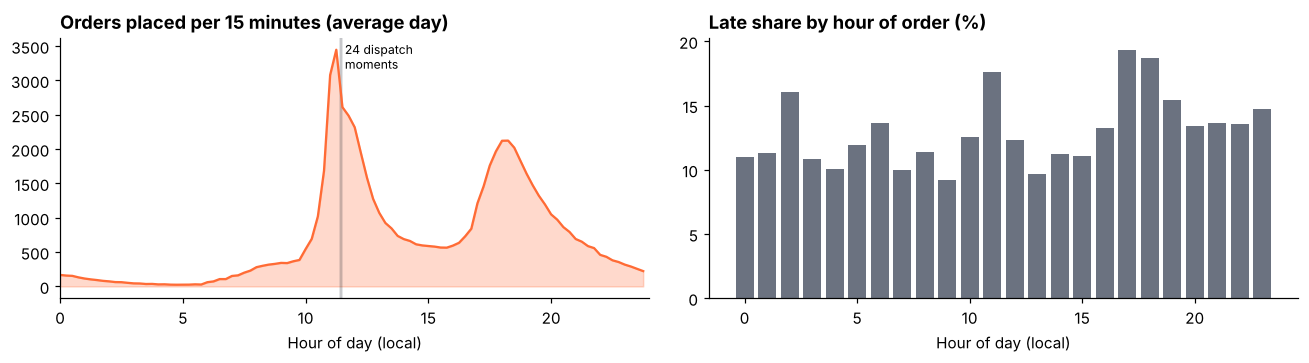

Peak: 3,448 orders per 15 min at 11:15


In [7]:
by15 = (((od.placed + 8 * 3600) % 86400) // 900).value_counts().sort_index() / wb.dt.nunique()
hh = ((done.placed + 8 * 3600) % 86400) // 3600
late_h = 100 * (delay > 0).groupby(hh).mean()
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.4))
a1.fill_between(by15.index / 4, by15.values, color=C_OPT, alpha=0.25); a1.plot(by15.index / 4, by15.values, color=C_OPT)
a1.axvspan(11 + 25/60, 11.5, color=C_INK, alpha=0.15); a1.text(11.6, by15.max() * 0.92, "24 dispatch\nmoments", fontsize=8)
a1.set_title("Orders placed per 15 minutes (average day)"); a1.set_xlabel("Hour of day (local)"); a1.set_xlim(0, 24)
a2.bar(late_h.index, late_h.values, color=C_MUTE); a2.set_title("Late share by hour of order (%)"); a2.set_xlabel("Hour of day (local)")
plt.tight_layout(); plt.savefig("figures/demand_profile.png", dpi=200, bbox_inches="tight"); plt.show()
print(f"Peak: {by15.max():,.0f} orders per 15 min at {int(by15.idxmax()//4):02d}:{int(by15.idxmax()%4*15):02d}")

## 3 · A digital twin of courier routes

To compare dispatch plans we need to predict what happens after an assignment. Our route simulator has two calibrated parameters:

1. **Travel speed and handover time**, fitted on 77,000 *single-order waves* (a courier picks up one order and delivers it directly): delivery minutes = handover + distance / speed.
2. **Restaurant dwell**, the extra minutes a courier loses at each pickup (queue, parking, a meal not quite ready). We fit it on the first four days of dispatch moments and **test on the last four**.

In [8]:
travel = calibrate_travel(wb, cw, orders)
travel["topk"] = 12
print(f"Direct trips: speed {travel['speed_kmh']:.1f} straight-line km/h, handover {travel['handover_min']:.1f} min (n = {travel['n']:,})")

T_ALL = sorted(dw.dispatch_time.unique())
T_USE = T_ALL[::4] if QUICK else T_ALL
epochs = [build_epoch(t0, wb, dw, dr, orders, travel) for t0 in T_ALL]
train = epochs[:12]; test = epochs[12:]

t = time.time()
dwell = fit_pickup_dwell(train, orders, travel)
travel_cal = with_dwell(travel, dwell)
print(f"Restaurant dwell fitted on days 1-4: {dwell:.2f} min per pickup ({time.time()-t:.0f}s)")

Direct trips: speed 12.8 straight-line km/h, handover 3.2 min (n = 77,120)


Restaurant dwell fitted on days 1-4: 1.79 min per pickup (35s)


In [9]:
rows = []
for name, E in [("Days 1-4 (fit)", train), ("Days 5-8 (held out)", test)]:
    for label, trv in [("direct-trip speed only", with_dwell(travel, 0.0)), ("+ restaurant dwell", travel_cal)]:
        v = validate(E, orders, trv, include_onhand=True)
        for kind, g in v.groupby("new"):
            e = g.pred - g.actual
            rows.append(dict(days=name, model=label, orders="newly dispatched" if kind else "already on hand", n=len(g),
                             bias_min=round(e.mean(), 2), mae_min=round(e.abs().mean(), 2), corr=round(np.corrcoef(g.pred, g.actual)[0, 1], 3),
                             late_pred_pct=round(100 * (g.pred > g.due).mean(), 1), late_actual_pct=round(100 * (g.actual > g.due).mean(), 1)))
        if label.startswith("+"):
            if name.startswith("Days 5"): v_test = v
            else: v_train = v
val_table = pd.DataFrame(rows)
val_table

,days,model,orders,n,bias_min,mae_min,corr,late_pred_pct,late_actual_pct
0,Days 1-4 (fit),direct-trip speed only,already on hand,9296,-0.72,5.81,0.815,17.1,21.9
1,Days 1-4 (fit),direct-trip speed only,newly dispatched,5451,-4.21,8.72,0.478,6.9,17.9
2,Days 1-4 (fit),+ restaurant dwell,already on hand,9296,2.86,6.77,0.813,33.6,21.9
3,Days 1-4 (fit),+ restaurant dwell,newly dispatched,5451,0.04,8.93,0.461,21.2,17.9
4,Days 5-8 (held out),direct-trip speed only,already on hand,9143,-0.62,5.55,0.825,16.6,21.1
5,Days 5-8 (held out),direct-trip speed only,newly dispatched,5439,-4.12,8.53,0.504,6.4,18.0
6,Days 5-8 (held out),+ restaurant dwell,already on hand,9143,2.83,6.60,0.821,33.0,21.1
7,Days 5-8 (held out),+ restaurant dwell,newly dispatched,5439,0.09,8.70,0.490,19.9,18.0


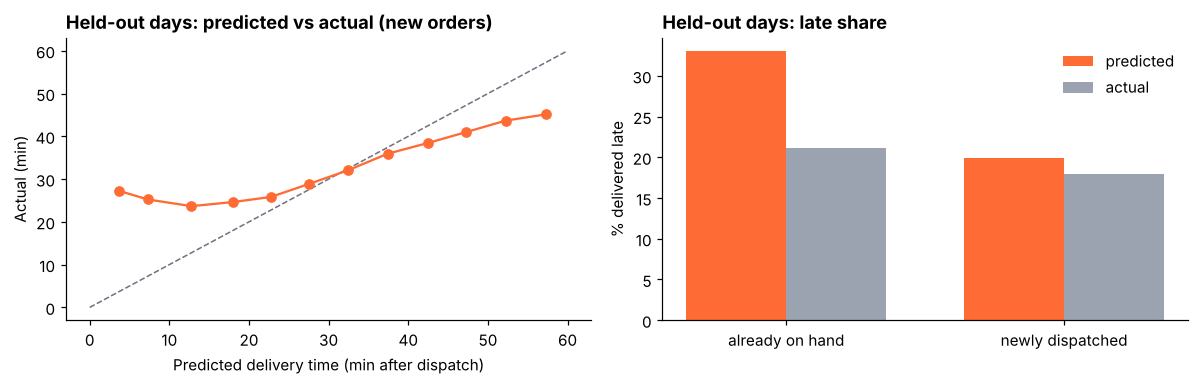

In [10]:
g = v_test[v_test.new]
bins = np.arange(0, 61, 5)
g = g.assign(b=pd.cut(g.pred, bins))
cal = g.groupby("b", observed=True).agg(pred=("pred", "mean"), actual=("actual", "mean"), n=("pred", "size"))
cal = cal[cal.n >= 30]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.6))
a1.plot([0, 60], [0, 60], color=C_MUTE, ls="--", lw=1)
a1.plot(cal.pred, cal.actual, marker="o", color=C_OPT)
a1.set_xlabel("Predicted delivery time (min after dispatch)"); a1.set_ylabel("Actual (min)")
a1.set_title("Held-out days: predicted vs actual (new orders)")
lt = val_table[(val_table.days.str.startswith("Days 5")) & (val_table.model.str.startswith("+"))]
x = np.arange(len(lt)); w = 0.36
a2.bar(x - w/2, lt.late_pred_pct, w, color=C_OPT, label="predicted"); a2.bar(x + w/2, lt.late_actual_pct, w, color=C_MT, label="actual")
a2.set_xticks(x); a2.set_xticklabels(lt.orders); a2.set_ylabel("% delivered late"); a2.legend(frameon=False)
a2.set_title("Held-out days: late share")
plt.tight_layout(); plt.savefig("figures/validation.png", dpi=200, bbox_inches="tight"); plt.show()

**Reading the validation.** For newly dispatched orders, which is what the dispatch decision controls, the twin is unbiased on days it never saw. For orders already on hand, it predicts more delay than actually happened: real couriers protect orders already in the bag better than a cheapest-insertion rule assumes. This bias applies to **every** plan, Meituan's included. We therefore report lateness of new orders and of on-hand orders **separately** and lean on the validated one.

### From predicted slack to a calibrated late probability

A single predicted time hides the twin's order-level error (about 9 minutes on average). So we do not count an order as late only when its predicted time passes the promise. Instead we fit **P(late | predicted slack)**, where slack = promised − predicted time, on days 1–4 and check it on days 5–8. Every plan, Meituan's and ours, is scored with the same curve.

In [11]:
w_late = fit_late_model(v_train[v_train.new])
vt = v_test[v_test.new]
p_te = late_prob(w_late, (vt.due - vt.pred).values)
print(f"Held-out days: predicted late share {p_te.mean():.1%} vs actual {(vt.actual > vt.due).mean():.1%} · AUC {auc((vt.actual > vt.due).values, p_te):.3f}")
xs = np.linspace(-20, 30, 6)
pd.DataFrame({"slack_min": xs, "P(late)": late_prob(w_late, xs).round(3)}).set_index("slack_min").T

Held-out days: predicted late share 17.8% vs actual 18.0% · AUC 0.575


slack_min,-20.0,-10.0,0.0,10.0,20.0,30.0
P(late),0.399,0.277,0.182,0.165,0.149,0.134


## 4 · The dispatch model

**Courier bids (columns).** At a dispatch moment with waiting orders $O$ and candidate couriers $C$, every courier $c$ bids on bundles $b$:

* every single order within 3 km for which $c$ is one of the 12 nearest eligible couriers;
* pairs from its 5 cheapest singles, and triples from its 3 cheapest (capacity: on-hand + new ≤ 8 orders, the 99th percentile in the data);
* Meituan's actual choice for that courier, so Meituan's plan is always feasible and the comparison is like-for-like.

The cost of a bid is **non-additive**: we re-route the courier with all bundle orders inserted, trying every insertion sequence:

$$\text{cost}_{cb} = \Delta\text{km}_{cb} + \lambda\,\Delta\text{late}_{cb} + \mu\,\mathbb{E}[\text{rejections}]_{cb}$$

**Set-partitioning model** (winner determination, as in the Mars combinatorial auction from sessions 8–9):

$$
\begin{aligned}
\min \;& \sum_{(c,b)} \text{cost}_{cb}\, z_{cb} \\
\text{s.t. }& \sum_{(c,b)\,:\,o \in b} z_{cb} = 1 && \forall o \in O \quad \text{(every order dispatched once)}\\
& \sum_{b} z_{cb} \le 1 && \forall c \in C \quad \text{(one bundle per courier per moment)}\\
& z_{cb} \in \{0,1\}
\end{aligned}
$$

We solve it in **Pyomo** with the free **HiGHS** solver (Gurobi is a one-word change: `SolverFactory("gurobi")`).

In [12]:
E_USE = [ep for ep in epochs if ep.t0 in set(T_USE)]
for ep in E_USE:
    ep.travel = travel_cal; ep.routes = {}
t = time.time()
cols = {ep.t0: generate_columns(ep, orders) for ep in E_USE}
gen_secs = time.time() - t
sizes = pd.concat([c["size"].clip(upper=4) for c in cols.values()]).value_counts().sort_index()
print(f"{len(E_USE)} dispatch moments · {np.mean([len(c) for c in cols.values()]):,.0f} bids per moment · "
      f"generated in {gen_secs/len(E_USE):.1f}s per moment")
print("bids by bundle size (4 = 4+):", sizes.to_dict())

24 dispatch moments · 15,175 bids per moment · generated in 9.7s per moment
bids by bundle size (4 = 4+): {1: 161326, 2: 179471, 3: 23208, 4: 206}


### Courier acceptance model

Couriers can reject an assignment (16% of Meituan's noon-peak dispatches were rejected). We fit a logistic model of acceptance on Meituan's actual dispatches from days 1–4 and test on days 5–8. The features are courier-to-merchant distance, on-hand orders, an idle flag (no on-hand orders), and the bid's added km and late minutes.

In [13]:
def meituan_pairs(ep, feats):
    c = cols[ep.t0]
    g = feats[feats.idx.isin(set(c.idx[c.meituan]))].copy()
    g["y"] = ep.orders.meituan_grabbed.reindex(g.order_id).values
    return g

feats = {ep.t0: acceptance_features(ep, cols[ep.t0]) for ep in E_USE}
tr_set = [ep for ep in E_USE if ep in train] or E_USE[:len(E_USE)//2]
te_set = [ep for ep in E_USE if ep in test] or E_USE[len(E_USE)//2:]
P_tr = pd.concat([meituan_pairs(ep, feats[ep.t0]) for ep in tr_set])
P_te = pd.concat([meituan_pairs(ep, feats[ep.t0]) for ep in te_set])
mu_x, sd_x = P_tr[ACC_FEATURES].mean(), P_tr[ACC_FEATURES].std()
Zs = lambda d: ((d[ACC_FEATURES] - mu_x) / sd_x).values
w_acc = fit_logit(Zs(P_tr), P_tr.y.values)
auc_tr, auc_te = auc(P_tr.y.values, predict_logit(w_acc, Zs(P_tr))), auc(P_te.y.values, predict_logit(w_acc, Zs(P_te)))
for ep in E_USE:
    feats[ep.t0]["p"] = predict_logit(w_acc, Zs(feats[ep.t0]))
print(f"Acceptance AUC: fit days {auc_tr:.3f} · held-out days {auc_te:.3f} · observed acceptance {pd.concat([P_tr, P_te]).y.mean():.1%}")
pd.Series(w_acc, index=["intercept"] + ACC_FEATURES, name="standardized coefficient").round(3).to_frame()

Acceptance AUC: fit days 0.689 · held-out days 0.663 · observed acceptance 83.6%


,standardized coefficient
intercept,1.790
dist_cm,0.544
onhand,-0.052
idle,-0.515
km,-0.040
late,-0.123


## 5 · Re-solving Meituan's 24 noon-peak dispatch moments

For every moment we solve:

* **Pyomo (λ = 1):** one late minute weighs the same as one added km;
* a **λ sweep** from 0 (distance only) to 5 (lateness-first), which traces the trade-off frontier;
* an **acceptance-aware** version with μ km-equivalent per expected rejection;
* a **one-order-per-courier** restriction, the simplification the challenge says platforms often use.

In [14]:
LAMS = [0, 0.1, 0.25, 0.5, 1, 2, 5]
MUS = [0, 1, 2, 5, 10, 20]
rows, sweep, accs = [], [], []
t_all = time.time()
for ep in E_USE:
    c = cols[ep.t0]; pa = feats[ep.t0]
    exp_rej = pa.assign(q=1 - pa.p).groupby("idx").q.sum()
    rec = dict(t0=ep.t0, waiting=ep.n_waiting, orders=len(ep.orders), couriers=len(ep.couriers), bids=len(c))
    rec.update({f"meituan_{k}": v for k, v in plan_summary(c, list(c.idx[c.meituan]), pa, w_late).items()})
    t = time.time(); M = DispatchModel(c, ep.orders.index); rec["build_s"] = time.time() - t
    rec["n_vars"], rec["n_cons"] = M.n_vars, M.n_cons
    for lam in LAMS:
        r = M.solve(lam=lam)
        s = plan_summary(c, r["chosen"], pa, w_late)
        sweep.append(dict(t0=ep.t0, lam=lam, seconds=r["seconds"], status=r["status"], **s))
        if lam == 1:
            rec.update({f"opt_{k}": v for k, v in s.items()}); rec["solve_s"] = r["seconds"]; rec["status"] = r["status"]
    for mu in MUS:
        r = M.solve(lam=1.0, mu=mu, exp_reject=exp_rej)
        accs.append(dict(t0=ep.t0, mu=mu, **plan_summary(c, r["chosen"], pa, w_late)))
    M1 = DispatchModel(c, ep.orders.index, max_size=1, unassigned_penalty=50)
    r1 = M1.solve(lam=1.0)
    rec.update({f"one_{k}": v for k, v in plan_summary(c, r1["chosen"], pa, w_late).items()}); rec["one_unassigned"] = len(r1["unassigned"])
    rows.append(rec)
E = pd.DataFrame(rows); SW = pd.DataFrame(sweep); AC = pd.DataFrame(accs)
print(f"All solves done in {time.time()-t_all:.0f}s · every solve optimal: {set(SW.status) == {'optimal'}}")
print(f"Model size per moment: {E.n_vars.mean():,.0f} binary variables, {E.n_cons.mean():,.0f} constraints · "
      f"HiGHS solve {E.solve_s.mean():.2f}s on average (max {E.solve_s.max():.2f}s)")

All solves done in 234s · every solve optimal: True
Model size per moment: 15,175 binary variables, 2,465 constraints · HiGHS solve 0.61s on average (max 0.87s)


In [15]:
# acceptance-aware plan: the smallest mu whose predicted acceptance matches Meituan's predicted acceptance
mt_acc = E.meituan_exp_accept.mean()
acc_by_mu = AC.groupby("mu").exp_accept.mean()
MU_STAR = next((m for m in MUS if acc_by_mu[m] >= mt_acc - 0.005), MUS[-1])
star = AC[AC.mu == MU_STAR].sum(numeric_only=True)

def plan_row(name, km, late_share, late_new, late_on, n_new_late, couriers, accept, multi):
    return dict(plan=name, added_km=km, exp_late_share_new=late_share, late_min_new_orders=late_new, late_min_onhand=late_on,
                new_orders_late_deterministic=n_new_late, couriers_used=couriers, predicted_acceptance=accept, multi_order_share=multi)

wavg = lambda d, col: float((d[col] * d.orders).sum() / d.orders.sum())
S = E.sum(numeric_only=True)
AS = AC[AC.mu == MU_STAR]
head = pd.DataFrame([
    plan_row("Meituan (actual)", S.meituan_km, wavg(E.assign(orders=E.meituan_orders), "meituan_exp_late_share"), S.meituan_late_new, S.meituan_late_onhand, S.meituan_new_orders_late, S.meituan_couriers, E.meituan_exp_accept.mean(), E.meituan_multi_share.mean()),
    plan_row("Pyomo, lambda = 1", S.opt_km, wavg(E.assign(orders=E.opt_orders), "opt_exp_late_share"), S.opt_late_new, S.opt_late_onhand, S.opt_new_orders_late, S.opt_couriers, E.opt_exp_accept.mean(), E.opt_multi_share.mean()),
    plan_row(f"Pyomo, acceptance-aware (mu = {MU_STAR})", star.km, wavg(AS, "exp_late_share"), star.late_new, star.late_onhand, star.new_orders_late, star.couriers, acc_by_mu[MU_STAR], AS.multi_share.mean()),
    plan_row("One order per courier", S.one_km, wavg(E.assign(orders=E.one_orders), "one_exp_late_share"), S.one_late_new, S.one_late_onhand, S.one_new_orders_late, S.one_couriers, E.one_exp_accept.mean(), 0.0),
]).set_index("plan")
base = head.loc["Meituan (actual)"]
for col in ["added_km", "exp_late_share_new", "late_min_new_orders", "late_min_onhand"]:
    head[col + "_vs_meituan_%"] = (100 * (head[col] / base[col] - 1)).round(1)
print(f"{int(S.orders):,} orders over {len(E)} dispatch moments; one-order-per-courier left {int(E.one_unassigned.sum())} orders unassigned")
head.round(3).T

12,994 orders over 24 dispatch moments; one-order-per-courier left 6 orders unassigned


plan,Meituan (actual),"Pyomo, lambda = 1","Pyomo, acceptance-aware (mu = 10)",One order per courier
added_km,15236.008,12330.929,14509.166,15863.264
exp_late_share_new,0.178,0.162,0.165,0.158
late_min_new_orders,15102.825,245.412,530.779,365.909
late_min_onhand,22265.093,292.442,909.091,835.312
new_orders_late_deterministic,2558.000,226.000,499.000,194.000
couriers_used,9340.000,9422.000,9769.000,12988.000
predicted_acceptance,0.838,0.750,0.843,0.749
multi_order_share,0.484,0.519,0.467,0.000
added_km_vs_meituan_%,0.000,-19.100,-4.800,4.100
exp_late_share_new_vs_meituan_%,0.000,-9.200,-7.700,-11.300


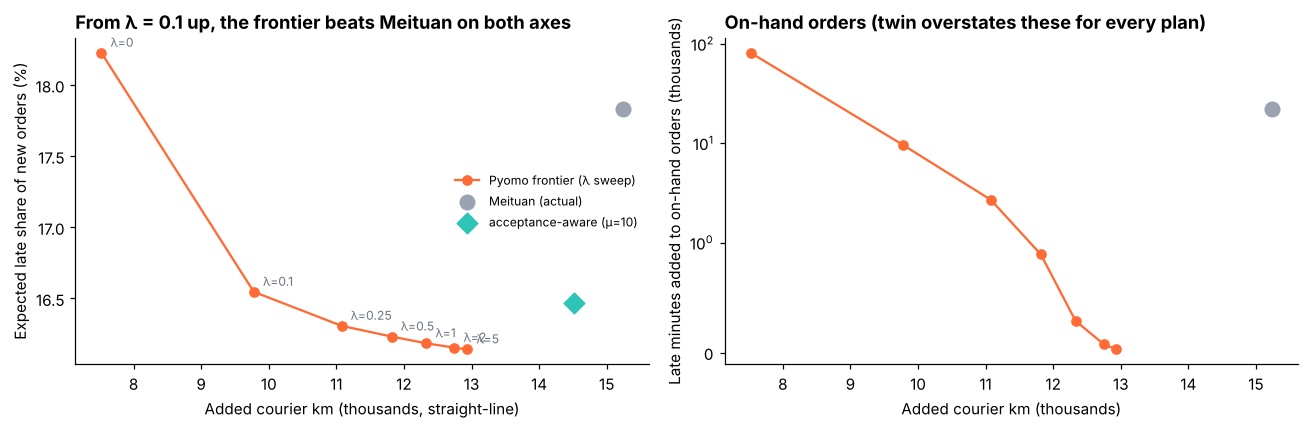

,km,late_new,late_onhand,exp_late_share
lam,,,,
0.00,7522.935,19662.420,81535.403,0.182
0.10,9778.685,2467.078,9623.138,0.165
0.25,11076.505,799.917,2705.254,0.163
0.50,11817.215,412.134,893.654,0.162
1.00,12330.929,245.412,292.442,0.162
2.00,12746.525,146.997,81.245,0.162
5.00,12936.142,128.813,34.243,0.161


In [16]:
fr = SW.groupby("lam")[["km", "late_new", "late_onhand"]].sum()
fr["exp_late_share"] = SW.assign(w=SW.exp_late_share * SW.orders).groupby("lam").w.sum() / SW.groupby("lam").orders.sum()
mt_share = head.loc["Meituan (actual)", "exp_late_share_new"]; st_share = head.iloc[2]["exp_late_share_new"]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
a1.plot(fr.km / 1000, 100 * fr.exp_late_share, marker="o", color=C_OPT, label="Pyomo frontier (λ sweep)")
for lam, r in fr.iterrows():
    a1.annotate(f"λ={lam:g}", (r.km / 1000, 100 * r.exp_late_share), textcoords="offset points", xytext=(6, 4), fontsize=8, color=C_MUTE)
a1.scatter([S.meituan_km / 1000], [100 * mt_share], s=90, color=C_MT, zorder=5, label="Meituan (actual)")
a1.scatter([star.km / 1000], [100 * st_share], s=90, color=C_ACC, marker="D", zorder=5, label=f"acceptance-aware (μ={MU_STAR})")
a1.set_xlabel("Added courier km (thousands, straight-line)"); a1.set_ylabel("Expected late share of new orders (%)")
a1.set_title("From λ = 0.1 up, the frontier beats Meituan on both axes"); a1.legend(frameon=False, fontsize=8)
a2.plot(fr.km / 1000, fr.late_onhand / 1000, marker="o", color=C_OPT); a2.scatter([S.meituan_km / 1000], [S.meituan_late_onhand / 1000], s=90, color=C_MT, zorder=5)
a2.set_yscale("symlog", linthresh=1); a2.set_xlabel("Added courier km (thousands)"); a2.set_ylabel("Late minutes added to on-hand orders (thousands)")
a2.set_title("On-hand orders (twin overstates these for every plan)")
plt.tight_layout(); plt.savefig("figures/frontier.png", dpi=200, bbox_inches="tight"); plt.show()
fr.round(3)

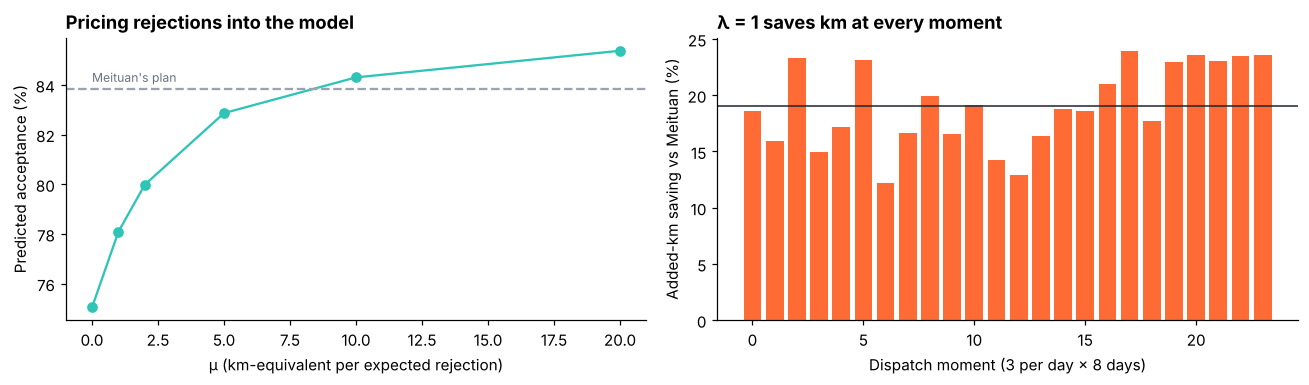

,km,late_new,accept,exp_late_share
mu,,,,
0,12330.929,245.412,0.750,0.162
1,12450.640,255.935,0.781,0.162
2,12737.042,265.526,0.800,0.163
5,13656.793,375.208,0.829,0.164
10,14509.166,530.779,0.843,0.165
20,15294.322,1065.141,0.854,0.166


In [17]:
ac = AC.groupby("mu").agg(km=("km", "sum"), late_new=("late_new", "sum"), accept=("exp_accept", "mean"))
ac["exp_late_share"] = AC.assign(w=AC.exp_late_share * AC.orders).groupby("mu").w.sum() / AC.groupby("mu").orders.sum()
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.6))
a1.plot(ac.index, 100 * ac.accept, marker="o", color=C_ACC); a1.axhline(100 * mt_acc, color=C_MT, ls="--"); a1.text(0, 100 * mt_acc + 0.3, "Meituan's plan", fontsize=8, color=C_MUTE)
a1.set_xlabel("μ (km-equivalent per expected rejection)"); a1.set_ylabel("Predicted acceptance (%)"); a1.set_title("Pricing rejections into the model")
sav = 100 * (1 - E.opt_km / E.meituan_km)
a2.bar(range(len(E)), sav, color=C_OPT); a2.axhline(sav.mean(), color=C_INK, lw=1)
a2.set_xlabel("Dispatch moment (3 per day × 8 days)"); a2.set_ylabel("Added-km saving vs Meituan (%)"); a2.set_title("λ = 1 saves km at every moment")
plt.tight_layout(); plt.savefig("figures/acceptance_and_moments.png", dpi=200, bbox_inches="tight"); plt.show()
ac.round(3)

## 6 · Results for the slides

The cell below writes the aggregates the deck uses: totals only, no raw data.

In [18]:
fr_out = fr.reset_index()
summary = dict(
    data_check=check.to_dict(orient="records"),
    peak_15min=float(by15.max()), by15=[round(float(x), 1) for x in by15.reindex(range(96), fill_value=0).values],
    travel=dict(speed_kmh=travel["speed_kmh"], handover_min=travel["handover_min"], n_trips=travel["n"], dwell_min=dwell),
    validation=val_table.to_dict(orient="records"),
    acceptance=dict(auc_fit=auc_tr, auc_test=auc_te),
    late_model=dict(test_pred_share=float(p_te.mean()), test_actual_share=float((vt.actual > vt.due).mean()), test_auc=float(auc((vt.actual > vt.due).values, p_te))),
    moments=len(E), orders=int(S.orders), waiting_mean=float(E.waiting.mean()), couriers_mean=float(E.couriers.mean()),
    bids_mean=float(E.bids.mean()), n_vars_mean=float(E.n_vars.mean()), n_cons_mean=float(E.n_cons.mean()),
    solve_mean_s=float(E.solve_s.mean()), solve_max_s=float(E.solve_s.max()), build_mean_s=float(E.build_s.mean()),
    gen_s_per_moment=gen_secs / len(E_USE),
    headline=head.reset_index().to_dict(orient="records"), mu_star=MU_STAR,
    frontier=fr_out.to_dict(orient="records"),
    acceptance_sweep=ac.reset_index().to_dict(orient="records"),
    km_saving_by_moment=[round(float(x), 2) for x in sav.values],
)
json.dump(summary, open("results_summary.json", "w"), indent=1, default=float)
print("saved results_summary.json and figures/")

saved results_summary.json and figures/


## 7 · Takeaways and limitations

**Takeaways.**

1. **Joint dispatch cuts courier distance by 19%.** Re-solving each noon-peak moment as one set-partitioning model saves added courier km at every one of the 24 moments (12% to 24%, 19.1% overall: 15,236 → 12,331 straight-line km for the same 12,994 orders). Punctuality is no worse: the expected late share of new orders goes from 17.8% to 16.2%.
2. **It is fast enough to run live.** About 15,000 binary variables and 2,500 constraints per moment; HiGHS solves each in 0.6 s on average (0.9 s at worst), well inside the challenge's 10-second window. Generating the bids takes about 10 s per moment in plain Python, and that part parallelizes by courier.
3. **Bundling is where the value is.** Forcing one order per courier, the simplification platforms use for speed, needs 12,988 courier assignments instead of 9,422 and 29% more distance than the bundle model (15,863 vs 12,331 km).
4. **Distance and courier acceptance pull against each other.** The cheapest plan predicts 75% acceptance against Meituan's 84%, mostly because it leans on idle couriers, who reject more. Pricing each expected rejection at 10 km restores 84.3% predicted acceptance while still saving 4.8% distance at a 16.5% expected late share.
5. **λ sets the operating point.** From λ = 0.1 to λ = 5, every plan beats Meituan on both distance and expected lateness. Distance-only (λ = 0) saves 51% of km but makes lateness slightly worse (18.2%).
6. **We do not over-claim on lateness.** In the deterministic twin, late minutes of new orders fall from 15,103 to 245. The twin misses individual orders by about 9 minutes, though, so the calibrated improvement in late share is modest. The robust gain is distance.

**Limitations.**

* *Same information, different process.* Meituan dispatches in 30–60 s cycles within each 180-second window. We assume one joint decision per window with the information available at the checkpoint, the same assumption the data paper uses.
* *Simulated outcomes.* Lateness comes from the calibrated twin. It is unbiased for newly dispatched orders but overstates delays to on-hand orders, for every plan.
* *Acceptance is observational.* The acceptance model only sees couriers Meituan chose to dispatch to, so predictions for unusual choices are less certain.
* *Distances are straight-line.* Road distances are typically 1.3–1.4 times longer; percentage comparisons are unaffected.

*This research was supported by data provided by Meituan.*